In [2]:
import pandas as pd

df = pd.read_csv("/home/guilherme/Documentos/wine-quality-classification/data/WineQT.csv")
print(df.shape, "\n *******")
print(df.info(), "\n *******")
print(df["quality"].value_counts().sort_index(), "\n *******")
print(df.duplicated().sum())
df.head()

(1143, 13) 
 *******
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
None 
 *******
quality
3      6
4     33
5    483
6    462
7    1

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
df = df.drop(columns=["Id"])

df["high_quality"] = (df["quality"] >= 7).astype(int)

print(df["high_quality"].value_counts())
print(df["high_quality"].value_counts(normalize=True).round(3))

high_quality
0    984
1    159
Name: count, dtype: int64
high_quality
0    0.861
1    0.139
Name: proportion, dtype: float64


EDA, parte 1: quem diferencia um vinho bom?

alcohol                 0.403676
citric acid             0.251146
sulphates               0.208020
fixed acidity           0.123212
residual sugar          0.064145
free sulfur dioxide    -0.055977
pH                     -0.073318
chlorides              -0.103985
total sulfur dioxide   -0.113373
density                -0.148670
volatile acidity       -0.304523
Name: high_quality, dtype: float64


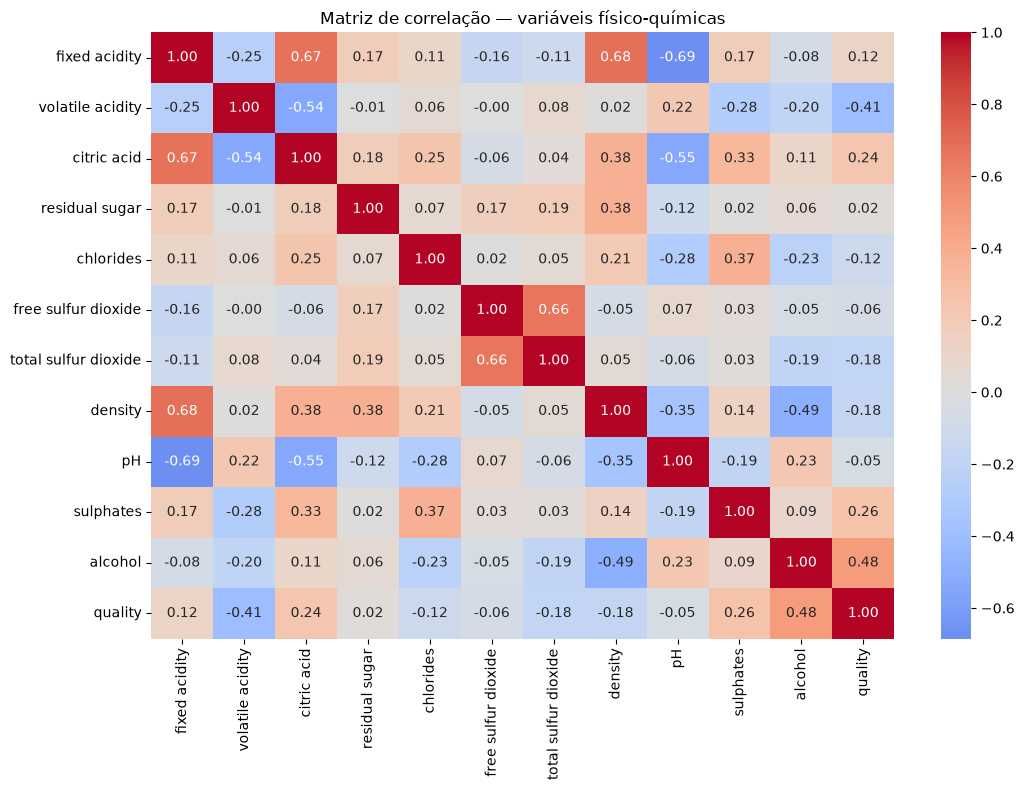

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# correlação de cada variável com o alvo
corr_alvo = df.corr(numeric_only=True)["high_quality"].drop(["high_quality", "quality"])
print(corr_alvo.sort_values(ascending=False))

# mapa de calor geral
plt.figure(figsize=(11, 8))
sns.heatmap(df.drop(columns=["high_quality"]).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação — variáveis físico-químicas")
plt.tight_layout()
plt.savefig("../results/01_matriz_correlacao.png", dpi=150)
plt.show()

EDA, parte 2: boxplots e outliers

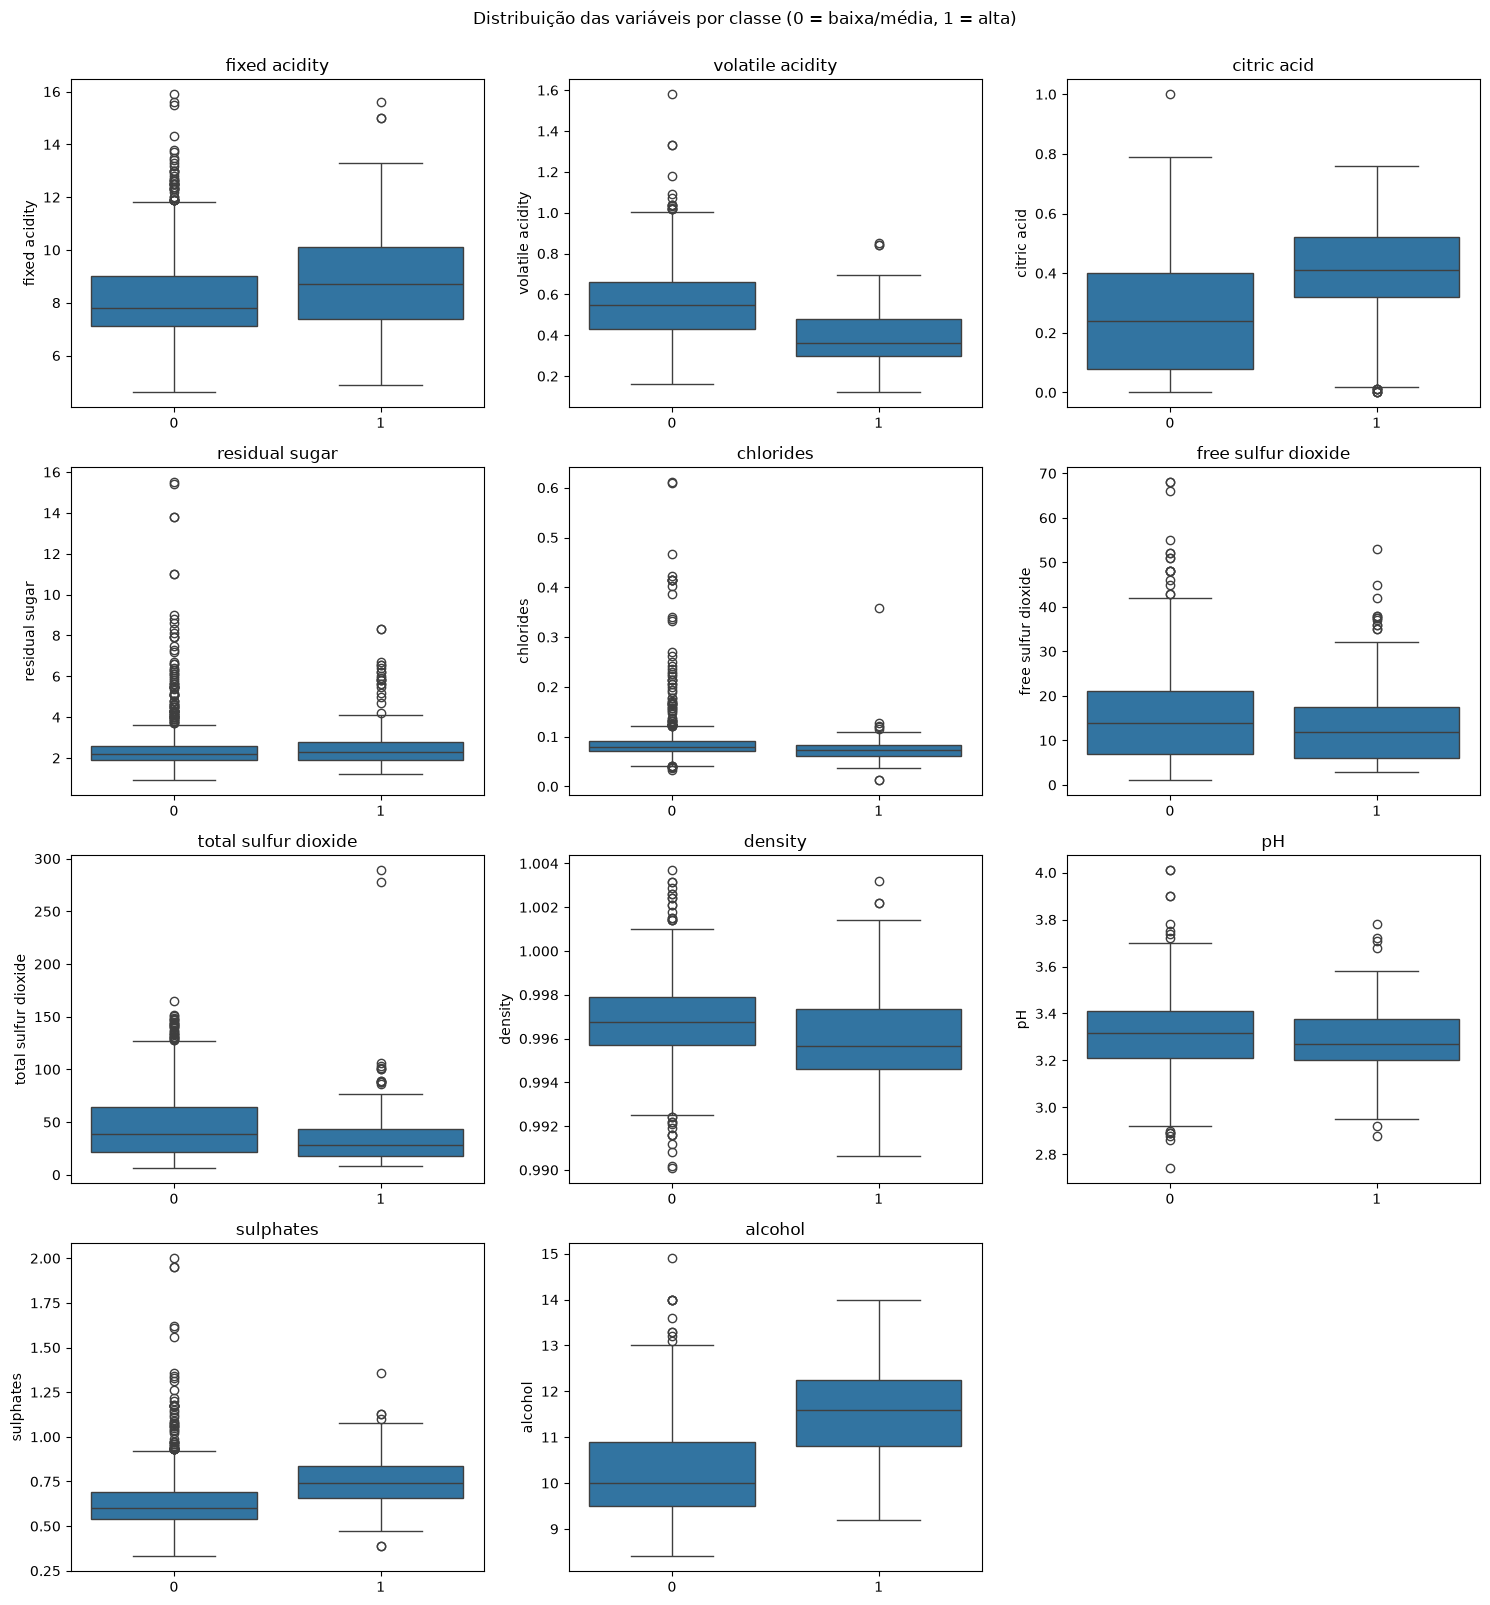

In [5]:
features = df.drop(columns=["quality", "high_quality"]).columns

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="high_quality", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.suptitle("Distribuição das variáveis por classe (0 = baixa/média, 1 = alta)", y=1.0)
plt.tight_layout()
plt.savefig("../results/02_boxplots_por_classe.png", dpi=150)
plt.show()

In [6]:
Q1, Q3 = df[features].quantile(0.25), df[features].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[features] < Q1 - 1.5*IQR) | (df[features] > Q3 + 1.5*IQR)).sum()
print(outliers.sort_values(ascending=False))

residual sugar          110
chlorides                77
fixed acidity            44
sulphates                43
total sulfur dioxide     40
density                  36
pH                       20
free sulfur dioxide      18
volatile acidity         14
alcohol                  12
citric acid               1
dtype: int64


Separação e pré-processamento

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality", "high_quality"])   # quality SAI daqui
y = df["high_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(914, 11) (229, 11)
high_quality
0    0.861
1    0.139
Name: proportion, dtype: float64
high_quality
0    0.86
1    0.14
Name: proportion, dtype: float64


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
)

logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("treinados")

treinados


In [9]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)

for nome, modelo in [("Regressão Logística", logreg), ("Random Forest", rf)]:
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    print(f"\n{'='*55}\n{nome}\n{'='*55}")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred,
          target_names=["Baixa/Média", "Alta"], digits=3))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")


Regressão Logística
[[161  36]
 [ 10  22]]
              precision    recall  f1-score   support

 Baixa/Média      0.942     0.817     0.875       197
        Alta      0.379     0.688     0.489        32

    accuracy                          0.799       229
   macro avg      0.660     0.752     0.682       229
weighted avg      0.863     0.799     0.821       229

ROC-AUC: 0.850

Random Forest
[[182  15]
 [ 12  20]]
              precision    recall  f1-score   support

 Baixa/Média      0.938     0.924     0.931       197
        Alta      0.571     0.625     0.597        32

    accuracy                          0.882       229
   macro avg      0.755     0.774     0.764       229
weighted avg      0.887     0.882     0.884       229

ROC-AUC: 0.912


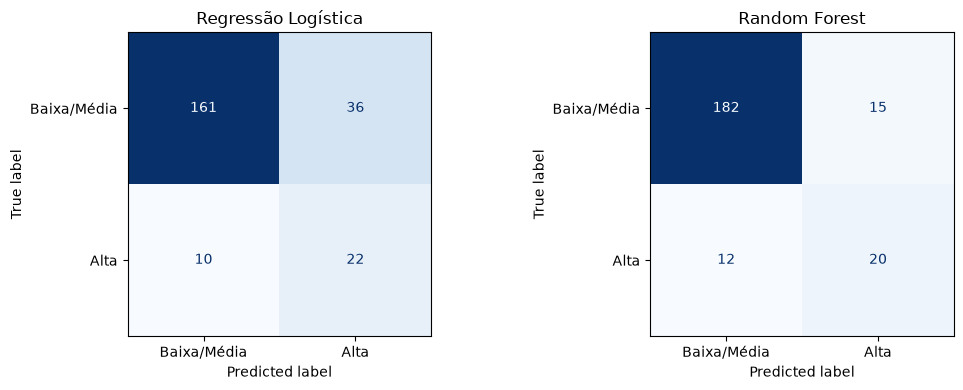

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, modelo) in zip(axes, [("Regressão Logística", logreg), ("Random Forest", rf)]):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, ax=ax,
        display_labels=["Baixa/Média", "Alta"], cmap="Blues", colorbar=False
    )
    ax.set_title(nome)
plt.tight_layout()
plt.savefig("../results/03_matrizes_confusao.png", dpi=150)
plt.show()

Validação cruzada e importância das variáveis

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nome, modelo in [("Regressão Logística", logreg), ("Random Forest", rf)]:
    auc = cross_val_score(modelo, X, y, cv=cv, scoring="roc_auc")
    f1  = cross_val_score(modelo, X, y, cv=cv, scoring="f1")
    print(f"{nome:22s} | AUC {auc.mean():.3f} (±{auc.std():.3f}) | F1 {f1.mean():.3f} (±{f1.std():.3f})")

Regressão Logística    | AUC 0.873 (±0.029) | F1 0.510 (±0.025)
Random Forest          | AUC 0.935 (±0.031) | F1 0.672 (±0.078)


Variáveis Importantes

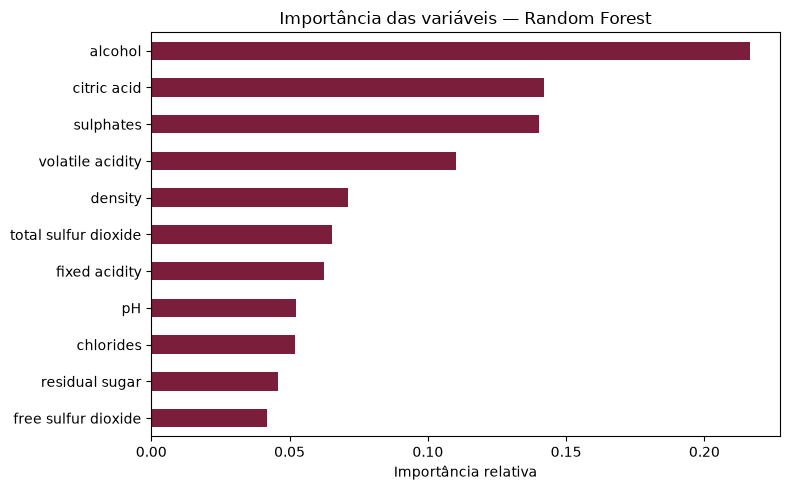

alcohol                 0.217
citric acid             0.142
sulphates               0.140
volatile acidity        0.110
density                 0.071
total sulfur dioxide    0.066
fixed acidity           0.062
pH                      0.052
chlorides               0.052
residual sugar          0.046
free sulfur dioxide     0.042
dtype: float64

Odds ratio (Logística):
alcohol                 2.694
sulphates               1.979
citric acid             1.626
residual sugar          1.390
free sulfur dioxide     1.274
fixed acidity           1.194
pH                      0.837
density                 0.740
chlorides               0.657
volatile acidity        0.627
total sulfur dioxide    0.595
dtype: float64


In [12]:
import numpy as np

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#7b1e3c")
plt.title("Importância das variáveis — Random Forest")
plt.xlabel("Importância relativa")
plt.tight_layout()
plt.savefig("../results/04_importancia_variaveis.png", dpi=150)
plt.show()

print(imp.sort_values(ascending=False).round(3))

# coeficientes da logística, em odds ratio
coef = pd.Series(logreg.named_steps["clf"].coef_[0], index=X.columns)
print("\nOdds ratio (Logística):")
print(np.exp(coef).sort_values(ascending=False).round(3))